# Analisi Multivariata

### Obiettivo 
In natura l'effetto congiunto di più fattori può portare ad amplificare l'effetto dei singoli

### Matrice di correlazione tra parametri ambientali 
matrice di correlazione di Spearman per individuare quali variabili tendono a variare insieme 
- correlazioni positive
- correlazioni negative
- correlazioni prossime a zero

### Visualizzazione tramite Heatmap 
Utilizza una scala cromata di colori per esprimere le relazioni tra le variabili 
A. HeatMap ambientale --> parametri CIS
B. HeatMap ambientale-biologica --> parametri CIS + Biovolume 



Goal: capire se sono cambiate le condizioni ambientali del Mar Adricatico pugliese negli anni e quali parametri hanno subito una maggior variazione

In [32]:
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import numpy as np

In [33]:
#CARICO IL DATAFRAME
#Carico il primo df
path=r'C:\\Users\\sofia\\Università\\Tirocinio\\Dati ARPA\\Arpa_Puglia_dataset\\Dataset_Ostreopsis-Aliena_2014-2023.xlsx'
df_ost = pd.read_excel(path, header=2, sheet_name=1)
# Rimuoviamo le colonne senza nome
df_ost = df_ost.loc[:, ~df_ost.columns.str.contains('^Unnamed')]
#preparazione dati 
df_ost['Data']= pd.to_datetime(df_ost['Data'], errors='coerce')
# .astype(str).str.strip() converte i valori della colonna in stringhe e rimuove eventuali spazi bianchi in modo da evitare errori di confronto causati da differenze di formattazione
df_ost['SITO'] = df_ost['SITO'].astype(str).str.strip()
#Visualizziamo la densità della microalga in termini di biovolume 
df_ost['Densità Ostreopsis ovata (cell/L)'] = pd.to_numeric(df_ost['Densità Ostreopsis ovata (cell/L)'], errors='coerce')
Biovolume_cellulare = 30000
df_ost['Biovolume (µm3/L)'] = df_ost['Densità Ostreopsis ovata (cell/L)'] * Biovolume_cellulare


#Carichiamo i dati del 2°foglio Excel     
df_cis= pd.read_excel(r"C:\Users\sofia\Università\Tirocinio\Dati ARPA\Arpa_Puglia_dataset\Dataset_CIS-Aliena-2014-2023.xlsx", sheet_name=1, header=2)  #header=2 indica che vogliamo leggere i dati a partire dalla riga 3 (l'indice parte da 0) e che la riga 3 contiene i nomi delle colonne
# .iloc[:-2] rimuove le ultime due righe del df (sono righe vuote che non contengono dati)
df_cis = df_cis.iloc[:-2]

#associamo la stazione di Ostreopis con la stazione più vicina della reta di monitaraggio CIS 
site_to_cis_map = {
    'APANI LIDO S.VINCENZO (BR)': 'MC_TG01',
    'TORRE CANNE DI FRONTE AL FARO (BR)': 'MC_VL01',
    'LA FORCATELLA PRIMA CASA BIANCA (BR)': 'MC_VL01',
}

#eliminiamo eventuali spazi bianchi in modo che colonne con la stessa intestazione non vengano mechate
df_cis.columns=(df_cis.columns.str.replace('\u00a0',' ', regex=False).str.replace(r'\s+',' ',regex=True).str.strip())
        #.str.replace() rimuove  agli argomenti e li sostituisce col secondo argomento
            #(\u00a0 sono spazi non visibili da excel che vengono rimossi e sostituiti con spazi visibili
            #(\s+) è un'espressione regolare che rappresenta uno o più spazi bianchi consecutivi, e li sostituisce con un singolo spazio
        #.str.strip() rimuove eventuali spazi bianchi all'inizio e alla fine dei nomi delle colonne


#creiamo una nuova colonna nel df_cis che contenga il nome della stazione Ost e il biovolume 
df_ost['Codice stazione'] = df_ost['SITO'].map(site_to_cis_map)

#preparazione df_cis
df_cis['Data']=pd.to_datetime(df_cis['Data'], errors='coerce')
df_cis = df_cis.sort_values('Data').copy()
df_cis['Temperatura (°C)'] = pd.to_numeric(df_cis['Temperatura (°C)'], errors='coerce')



#Rinominazione colonna per uniformare i nomi delle colonne tra i due df e facilitare il merge 
df_ost = df_ost.rename(columns={'QUOTA': 'Quota prelievo'})

# Normalizziamo i nomi delle colonne per evitare errori dovuti a spazio/maiuscole
df_cis['Codice stazione'] = df_cis['Codice Stazione'].astype(str).str.strip()
df_cis['Quota prelievo'] = df_cis['Quota prelievo'].astype(str).str.strip().str.upper()

# Uniformiamo la quota nel df_ost al formato del CIS (FONDO/SUPERFICIE)
quota_map = {'Acque fondo': 'FONDO', 'Acque colonna': 'SUPERFICIE'}
df_ost['Quota prelievo'] = df_ost['Quota prelievo'].astype(str).str.strip().map(quota_map)

# selezioniamo solo le colonne di interesse nel df_cis e ne creiamo una copia + applichiamo dropna per evitare celle vuote/NaN  
df_cis = df_cis[['Data',
                'Codice stazione',
                'Quota prelievo',
                'Temperatura (°C)',
                'Salinità (PSU)',
                'pH (unità)',
                'Ossigeno disciolto (O2) (mg/l)',
                'Clorofilla (µg/l)',
                'Azoto totale (N) (µg/l)',
                'Azoto ammoniacale (N-NH4) (µg/l)',
                'Azoto nitrico (N-NO3) (µg/l)',
                'Fosforo totale (P) (µg/l)'
                ]].dropna(subset=['Data', 'Codice stazione','Quota prelievo']).copy()
                    #.dropna(subset=[]) richiede che queste variabili siano presenti e non siano NaN per poter effettuare il merge, se manca una sola delle variabili viene eliminata la riga
                          #per effettuare il merge è sufficiente che le colonne chiave non siano NaN (Data, codice stazione, quota prelievo)  
                            
parametri_cis = [
    'Temperatura (°C)',
    'Salinità (PSU)',
    'pH (unità)',
    'Ossigeno disciolto (O2) (mg/l)',
    'Clorofilla (µg/l)',
    'Azoto totale (N) (µg/l)',
    'Azoto ammoniacale (N-NH4) (µg/l)',
    'Azoto nitrico (N-NO3) (µg/l)',
    'Fosforo totale (P) (µg/l)',
    ]

# I valori inferiori a una certa soglia vengono sostituiti con la metà della soglia, in modo di non avere valori nulli ma cmq trascurabili
import re
for colonna in parametri_cis:
    # Sostituisco i valori del tipo <X con la metà di X
    df_cis[colonna] = df_cis[colonna].replace(
        r'^\s*<\s*(\d+(?:[.,]\d+)?)\s*$',
        lambda x: float(x.group(1).replace(',', '.')) / 2,
        regex=True
    )
    # Converto la colonna in numerica
    df_cis[colonna] = pd.to_numeric(
        df_cis[colonna],
        errors='coerce'
    )

df_cis = df_cis.sort_values('Data')
df_ost = df_ost.dropna(subset=['Data','SITO','Codice stazione','Quota prelievo']).sort_values('Data')


#Rinomian le colonne delle date per vedere la distanza temporale tra i campionamenti dell'alga e dell'acqua
df_ost = df_ost.rename(columns={'Data': 'Data_ost'})
df_cis = df_cis.rename(columns={'Data': 'Data_CIS'})


df = pd.merge_asof(
    df_ost,
    df_cis,
    left_on='Data_ost',
    right_on='Data_CIS',
    by=['Codice stazione', 'Quota prelievo'],
    direction ='nearest',
    tolerance= pd.Timedelta(days=30)
)

#Calcoliamo la distanza temporale tra i campionamenti 
df['Distanza temporale (giorni)'] = (df['Data_ost'] - df['Data_CIS']).dt.days.abs().astype('Int64')


# Riordino colonne in modo che sia più intuitiva la visualizzazione
    #a. lista colonne df
columns = df.columns.tolist()
    # b. lista delle colonne da spostare
columns_to_move = [
    'Codice stazione',
    'Quota prelievo',
    'Data_ost',
    'Data_CIS',
    'Distanza temporale (giorni)'
]
    #c. ciclo for in cui scorriamo la lista delle colonne da spostare 
for col in columns_to_move:
    #d. rimuovo la corrispondente colonna dalla lista delle colonne del df
    columns.remove(col)     
    #e. trova la posizione della colonna 'SITO', aggiungendo +1 individua la posizione sucesiva
pos = columns.index('SITO') + 1
    #e. la inserisce  nella posizione trovata
columns[pos:pos] = columns_to_move
    #f. riordina il df secondo la nuova lista di colonne
df = df[columns]

display(df)


,ANNO,PROVINCIA,SITO,Codice stazione,Quota prelievo,Data_ost,Data_CIS,Distanza temporale (giorni),Densità Ostreopsis ovata (cell/L),Biovolume (µm3/L),Temperatura (°C),Salinità (PSU),pH (unità),Ossigeno disciolto (O2) (mg/l),Clorofilla (µg/l),Azoto totale (N) (µg/l),Azoto ammoniacale (N-NH4) (µg/l),Azoto nitrico (N-NO3) (µg/l),Fosforo totale (P) (µg/l)
0,2014,BR,APANI LIDO S.VINCENZO (BR),MC_TG01,FONDO,2014-06-13,2014-06-24,11,500,15000000,22.12,37.65,8.11,8.34,0.01,149.0,14.1,29.6,NaN
1,2014,BR,APANI LIDO S.VINCENZO (BR),MC_TG01,SUPERFICIE,2014-06-13,2014-06-24,11,320,9600000,22.66,37.49,8.07,8.38,0.01,175.0,19.0,35.9,NaN
2,2014,BR,TORRE CANNE DI FRONTE AL FARO (BR),MC_VL01,SUPERFICIE,2014-06-13,2014-05-28,16,0,0,20.33,37.21,8.06,5.75,0.02,184.0,36.1,28.7,5.4
3,2014,BR,TORRE CANNE DI FRONTE AL FARO (BR),MC_VL01,FONDO,2014-06-13,2014-05-28,16,200,6000000,19.52,37.63,8.11,5.75,0.30,253.0,86.3,22.8,NaN
4,2014,BR,LA FORCATELLA PRIMA CASA BIANCA (BR),MC_VL01,FONDO,2014-06-13,2014-05-28,16,200,6000000,19.52,37.63,8.11,5.75,0.30,253.0,86.3,22.8,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
475,2023,BR,LA FORCATELLA PRIMA CASA BIANCA (BR),MC_VL01,SUPERFICIE,2023-09-22,NaT,<NA>,953,28590000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
476,2023,BR,LA FORCATELLA PRIMA CASA BIANCA (BR),MC_VL01,FONDO,2023-09-22,NaT,<NA>,80089,2402670000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
477,2023,BR,TORRE CANNE DI FRONTE AL FARO (BR),MC_VL01,FONDO,2023-09-22,NaT,<NA>,152251,4567530000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
478,2023,BR,APANI LIDO S.VINCENZO (BR),MC_TG01,SUPERFICIE,2023-09-22,NaT,<NA>,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


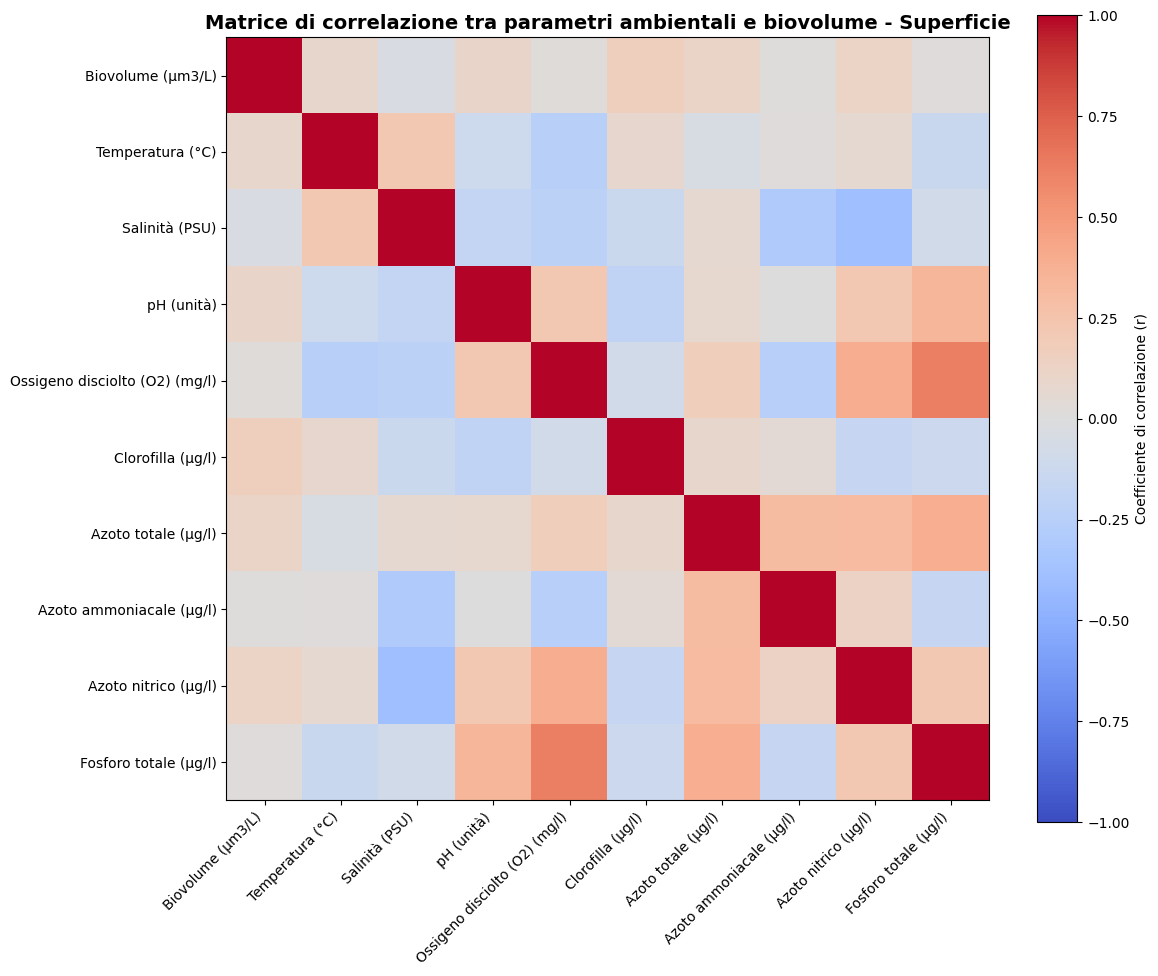

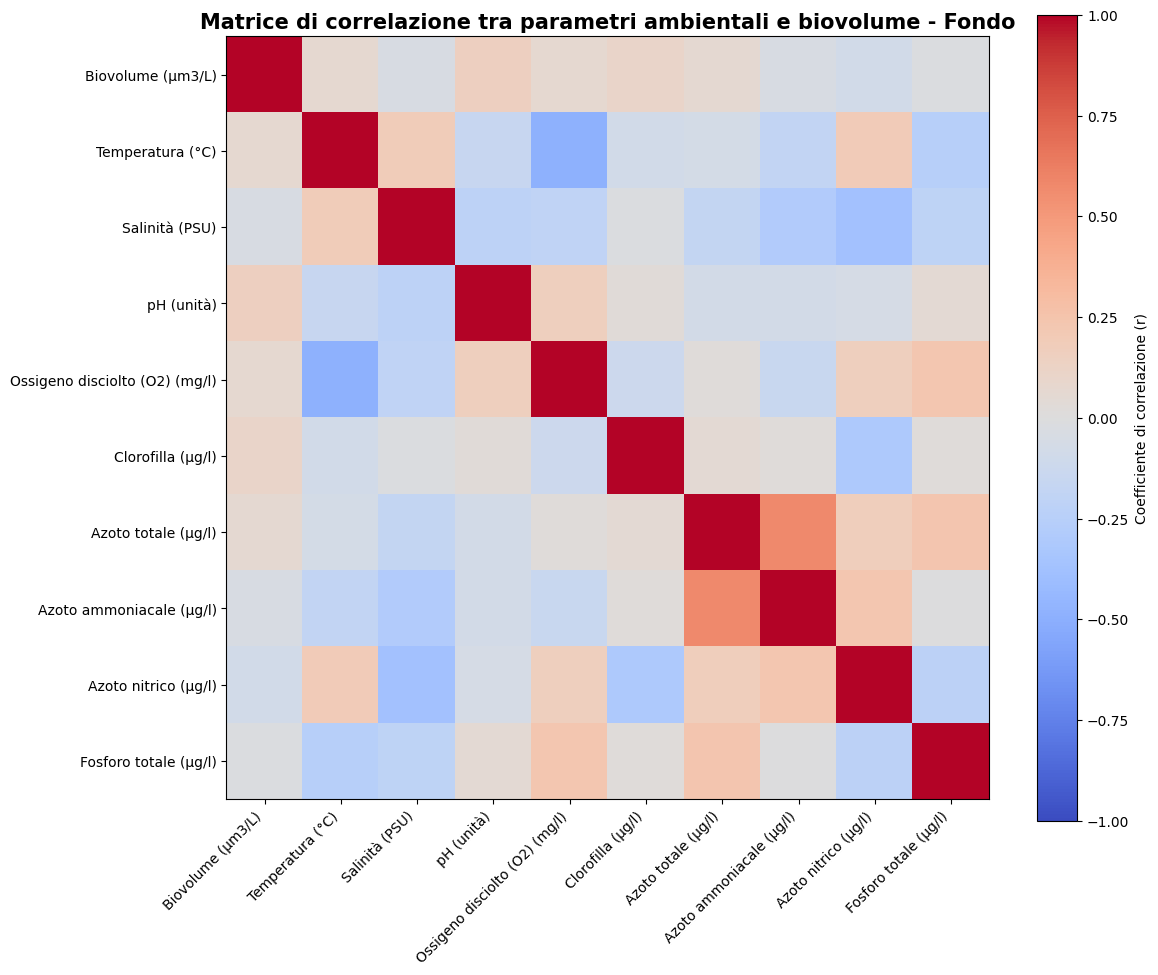

In [43]:
# Parametri ambientali + biovolume
parametri= [
    'Biovolume (µm3/L)',
    'Temperatura (°C)',
    'Salinità (PSU)',
    'pH (unità)',
    'Ossigeno disciolto (O2) (mg/l)',
    'Clorofilla (µg/l)',
    'Azoto totale (N) (µg/l)',
    'Azoto ammoniacale (N-NH4) (µg/l)',
    'Azoto nitrico (N-NO3) (µg/l)',
    'Fosforo totale (P) (µg/l)'
]
#definisco le etichette da visualizzare nella heatmap
etichette = [
    'Biovolume (µm3/L)',
    'Temperatura (°C)',
    'Salinità (PSU)',
    'pH (unità)',
    'Ossigeno disciolto (O2) (mg/l)',
    'Clorofilla (µg/l)',
    'Azoto totale (µg/l)',
    'Azoto ammoniacale (µg/l)',
    'Azoto nitrico (µg/l)',
    'Fosforo totale (µg/l)'
]


# Selezione dei campioni di superficie
dati_sup = df[df['Quota prelievo'] == 'SUPERFICIE'].copy()

# Calcolo della matrice di correlazione
matrice_corr1 = dati_sup[parametri].corr(method='pearson')
# Creazione della heatmap
fig, ax = plt.subplots(figsize=(12, 10))

im = ax.imshow(
    matrice_corr1,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)
fig.colorbar(im, ax=ax, label='Coefficiente di correlazione (r)')
ax.set_xticks(np.arange(len(parametri)))
ax.set_yticks(np.arange(len(parametri)))
ax.set_xticklabels(etichette, rotation=45, ha='right')
ax.set_yticklabels(etichette)
ax.set_title('Matrice di correlazione tra parametri ambientali e biovolume - Superficie',fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


# Grafico per il fondale
dati_fondo = df[df['Quota prelievo'] == 'FONDO'].copy()
matrice_corr2 = dati_fondo[parametri].corr(method='pearson')

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(
    matrice_corr2,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)
fig.colorbar(im, ax=ax, label='Coefficiente di correlazione (r)')

ax.set_xticks(np.arange(len(parametri)))
ax.set_yticks(np.arange(len(parametri)))

ax.set_xticklabels(etichette, rotation=45, ha='right')
ax.set_yticklabels(etichette)

ax.set_title('Matrice di correlazione tra parametri ambientali e biovolume - Fondo', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


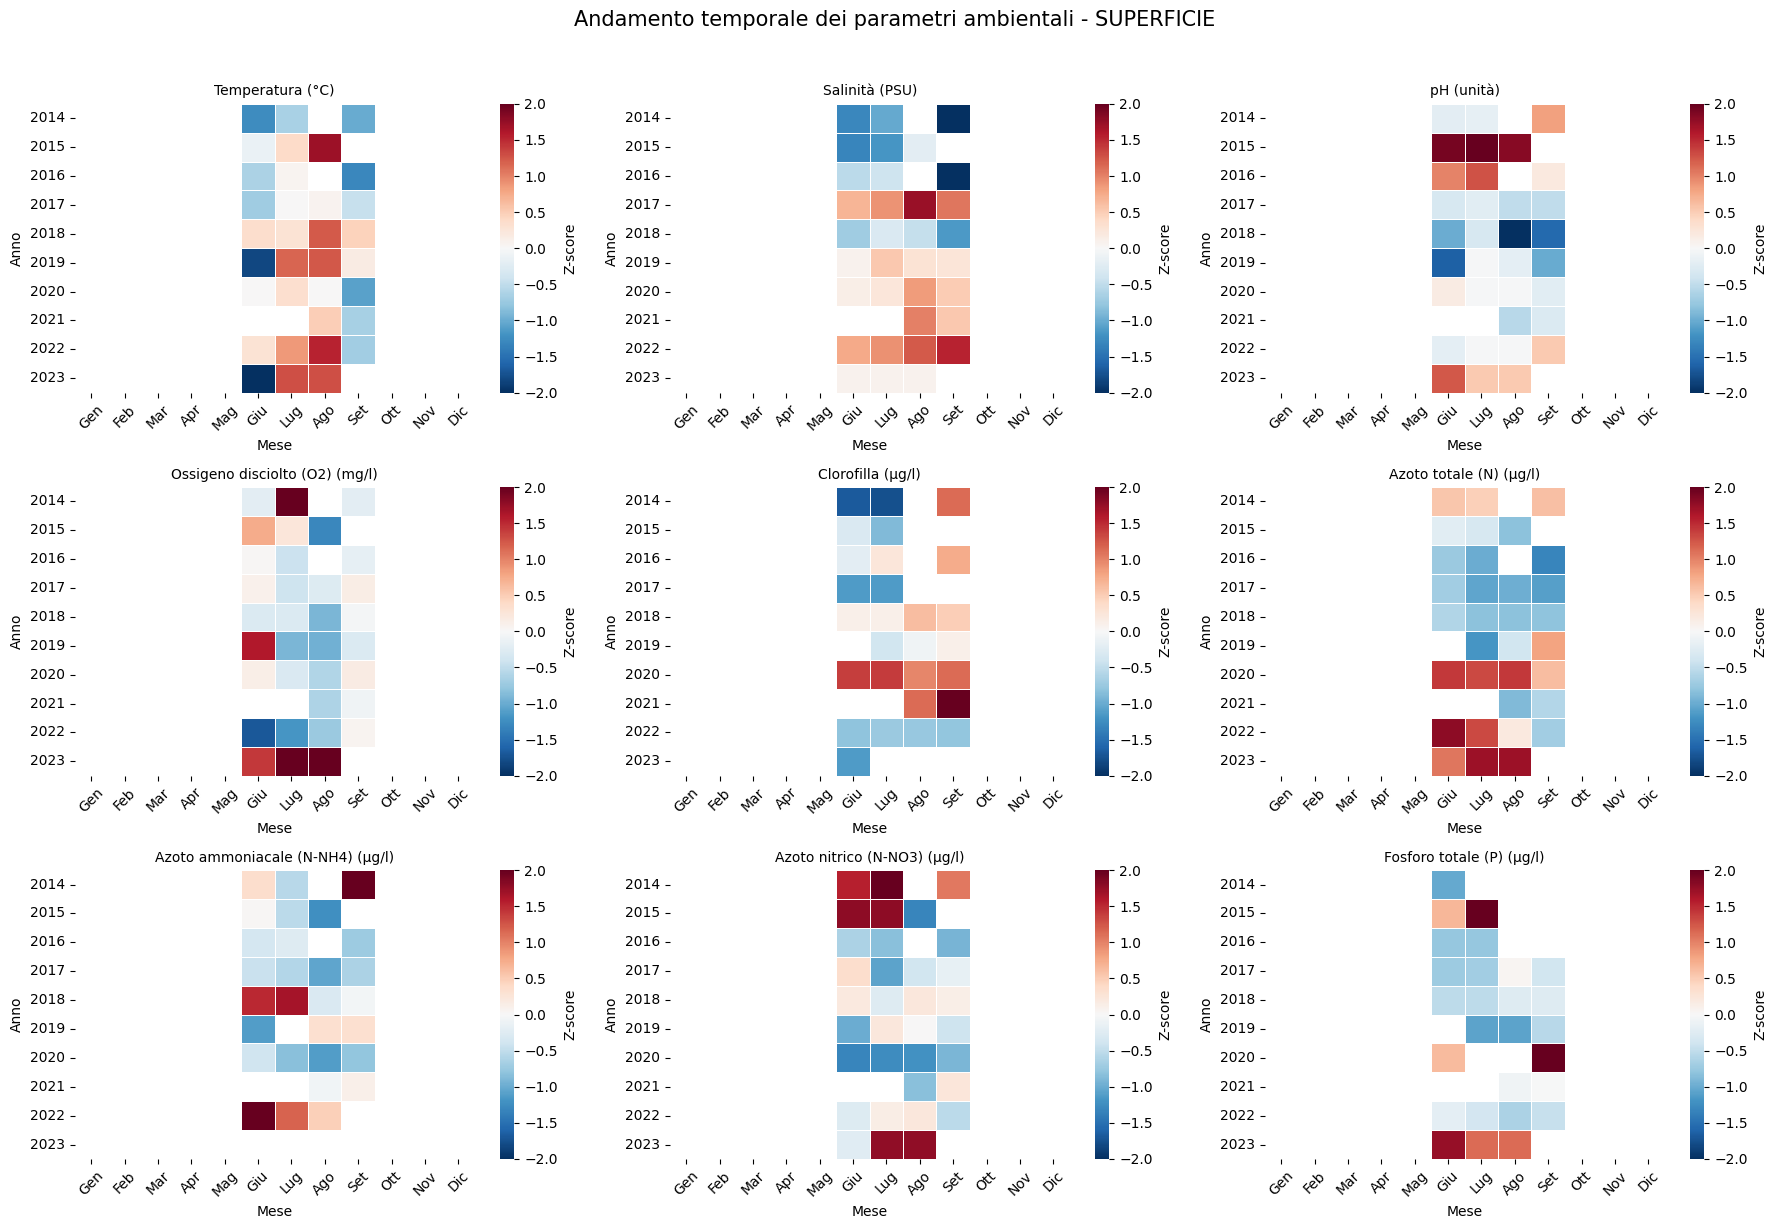

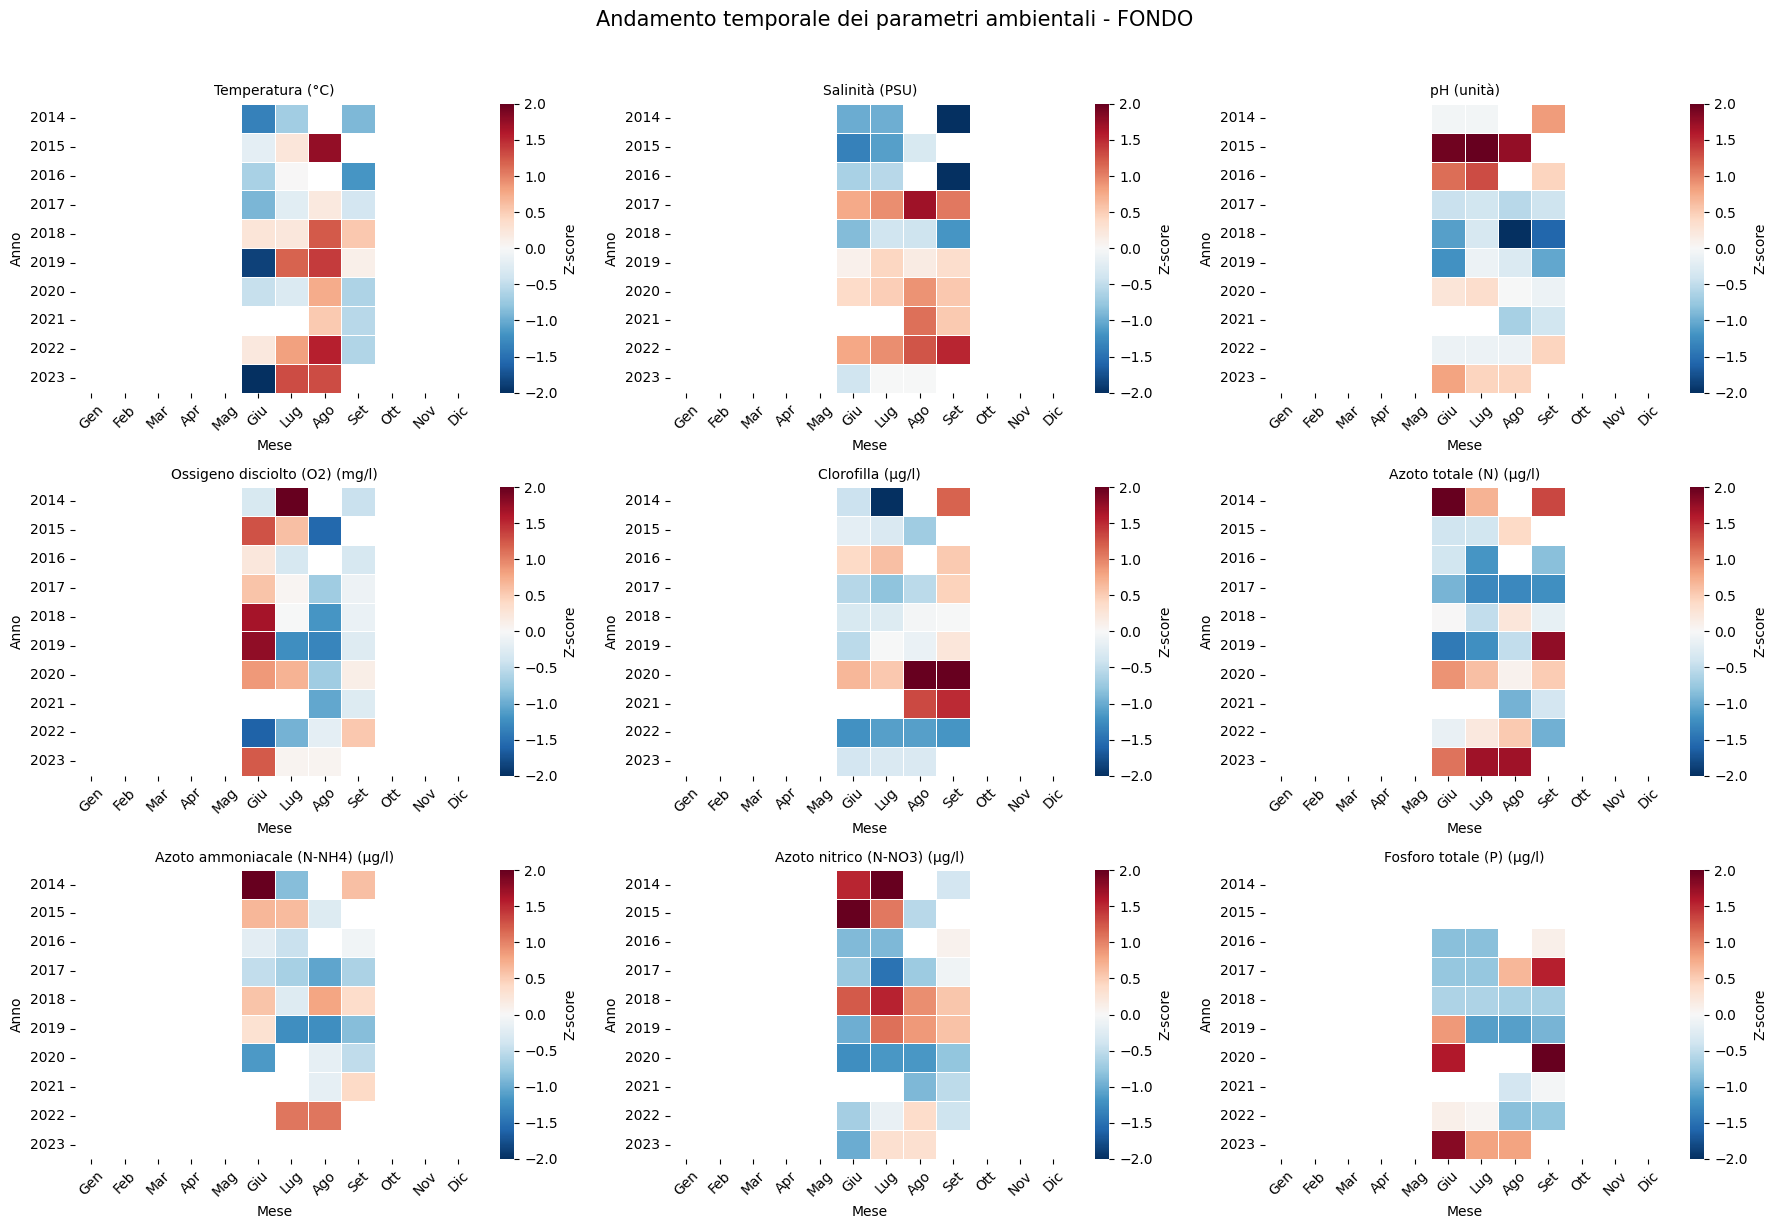

In [44]:

# Selezioniamo i campioni Ostreopsis associati a un campione CIS
df_heat = df.dropna(subset=['Data_CIS']).copy()

# Estraiamo anno e mese dalla data del campionamento biologico
df_heat['Anno'] = df_heat['Data_ost'].dt.year
df_heat['Mese'] = df_heat['Data_ost'].dt.month

parametri_cis = [
    'Temperatura (°C)',
    'Salinità (PSU)',
    'pH (unità)',
    'Ossigeno disciolto (O2) (mg/l)',
    'Clorofilla (µg/l)',
    'Azoto totale (N) (µg/l)',
    'Azoto ammoniacale (N-NH4) (µg/l)',
    'Azoto nitrico (N-NO3) (µg/l)',
    'Fosforo totale (P) (µg/l)'
]

def crea_heatmap(df, quota, parametri):

    # Selezioniamo i campioni relativi alla quota desiderata
    dati_quota = df[df['Quota prelievo'] == quota].copy()

    # Creiamo una figura con 9 sottografici (3 righe x 3 colonne)
    fig, axes = plt.subplots(
        nrows=3,
        ncols=3,
        figsize=(18, 12)
    )

    # Scorriamo i parametri ambientali e i relativi sottografici
    for ax, param in zip(axes.flat, parametri):

        # Calcoliamo la media del parametro per ogni combinazione anno-mese
        pivot = dati_quota.pivot_table(
            index='Anno',
            columns='Mese',
            values=param,
            aggfunc='mean'
        )

        # Manteniamo tutti gli anni e tutti i mesi
        pivot = pivot.reindex(
            index=range(2014, 2024),
            columns=range(1, 13)
        )

        # Calcoliamo media e deviazione standard dei valori aggregati
        media = np.nanmean(pivot.values)
        deviazione = np.nanstd(pivot.values)

        # Standardizzazione Z-score
        if np.isfinite(deviazione) and deviazione > 0:
            pivot_z = (pivot - media) / deviazione
        else:
            pivot_z = pivot.copy() * np.nan

        # Creiamo la heatmap
        sns.heatmap(
            pivot_z,
            ax=ax,
            cmap='RdBu_r',
            center=0,
            vmin=-2,
            vmax=2,
            linewidths=0.5,
            cbar_kws={'label': 'Z-score'}
        )

        ax.set_title(param, fontsize=10)
        ax.set_xlabel('Mese')
        ax.set_ylabel('Anno')

        # Nomi dei mesi
        ax.set_xticklabels(
            ['Gen', 'Feb', 'Mar', 'Apr', 'Mag', 'Giu',
             'Lug', 'Ago', 'Set', 'Ott', 'Nov', 'Dic'],
            rotation=45
        )

    # Titolo generale
    fig.suptitle(
        f'Andamento temporale dei parametri ambientali - {quota}',
        fontsize=15,
        y=1.02
    )

    plt.tight_layout()
    plt.show()

    # Heatmap delle acque superficiali
crea_heatmap(df_heat, 'SUPERFICIE', parametri_cis)

# Heatmap delle acque di fondo
crea_heatmap(df_heat, 'FONDO', parametri_cis)

### PCA - *Principal Component Analysis*
per individuare le principali combinazioni di condizioni ambientali e verificare dove si collocano i campioni con biovolume elevato 

- rappresenta i parametri ambientali come vettori 
- utilizza nuove variabili che rappresentano la correlazioni tra le variabili iniziali 


! udm sono differenti, pertanto occorre una standardizzazione (Z-score?)

In [35]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

dati_standardizzati = scaler.fit_transform(dati_parametri)

ModuleNotFoundError: No module named 'sklearn'

### Regressione multivariata ?
Modello che utilizzi il biovolume come variabile dipendente e i parametru ambientali come variabili esplicative

### Interpretazione Ecologica 
Goal: confrontare i risultati per individuare le condizioni ambientali maggiormente associate allo sviluppo di Ostreopis ovata